In [2]:

from google.colab import files

uploaded = files.upload()


Saving clean_customers.csv to clean_customers (1).csv


In [3]:

from google.colab import files

uploaded = files.upload()

Saving clean_orders.csv to clean_orders.csv


In [4]:

import pandas as pd

# Lấy tên file vừa tải lên
filename = next(iter(uploaded))

# Đọc CSV hoặc Excel
if filename.lower().endswith(".csv"):
    df = pd.read_csv(filename)
elif filename.lower().endswith((".xlsx", ".xls")):
    df = pd.read_excel(filename)
else:
    raise ValueError("Chỉ hỗ trợ CSV hoặc Excel")

print("Số dòng và số cột:", df.shape)

print("\nDanh sách các cột:")
print(df.columns.tolist())

print("\n5 dòng dữ liệu đầu tiên:")
display(df.head())

print("\nKiểu dữ liệu:")
print(df.dtypes)

print("\nGiá trị thiếu:")
print(df.isnull().sum())


Số dòng và số cột: (5945, 7)

Danh sách các cột:
['order_id', 'customer_id', 'order_date', 'status', 'shipping_address', 'total_amount', 'items']

5 dòng dữ liệu đầu tiên:


,order_id,customer_id,order_date,status,shipping_address,total_amount,items
0,1,365,2026-01-13 03:08:00,Completed,"456 Lê Duẩn, Quận Thanh Khê, Đà Nẵng",3370000.0,"[{'product_id': '66e3c0012222222222222203', 'p..."
1,2,254,2026-07-04 14:05:00,Completed,Chưa cập nhật,8590000.0,"[{'product_id': '66e3c0012222222222222204', 'p..."
2,3,708,2026-07-31 17:56:00,Completed,"81 Khóm 13 Bà Triệu, Phường 5, Quận 5, Đà Nẵng",7970000.0,"[{'product_id': '66e3c0012222222222222204', 'p..."
3,4,291,2026-07-15 12:33:00,Pending,Chưa cập nhật,560000.0,"[{'product_id': '66e3c0012222222222222209', 'p..."
4,5,785,2026-09-18 17:49:00,Pending,"123 Nguyễn Văn Cừ, Quận 5, TP.HCM",3090000.0,"[{'product_id': '66e3c0012222222222222203', 'p..."



Kiểu dữ liệu:
order_id              int64
customer_id           int64
order_date           object
status               object
shipping_address     object
total_amount        float64
items                object
dtype: object

Giá trị thiếu:
order_id            0
customer_id         0
order_date          0
status              0
shipping_address    0
total_amount        0
items               0
dtype: int64


In [5]:

from google.colab import files

uploaded = files.upload()



Saving clean_products.csv to clean_products.csv


In [6]:

from google.colab import files

uploaded = files.upload()


Saving clean_reviews.csv to clean_reviews.csv


In [7]:

import pandas as pd
import numpy as np

orders = pd.read_csv("clean_orders.csv")
customers = pd.read_csv("clean_customers.csv")
products = pd.read_csv("clean_products.csv")
reviews = pd.read_csv("clean_reviews.csv")

print("Orders:", orders.shape)
print("Customers:", customers.shape)
print("Products:", products.shape)
print("Reviews:", reviews.shape)

display(orders.head())


Orders: (5945, 7)
Customers: (1000, 5)
Products: (7, 3)
Reviews: (2000, 6)


,order_id,customer_id,order_date,status,shipping_address,total_amount,items
0,1,365,2026-01-13 03:08:00,Completed,"456 Lê Duẩn, Quận Thanh Khê, Đà Nẵng",3370000.0,"[{'product_id': '66e3c0012222222222222203', 'p..."
1,2,254,2026-07-04 14:05:00,Completed,Chưa cập nhật,8590000.0,"[{'product_id': '66e3c0012222222222222204', 'p..."
2,3,708,2026-07-31 17:56:00,Completed,"81 Khóm 13 Bà Triệu, Phường 5, Quận 5, Đà Nẵng",7970000.0,"[{'product_id': '66e3c0012222222222222204', 'p..."
3,4,291,2026-07-15 12:33:00,Pending,Chưa cập nhật,560000.0,"[{'product_id': '66e3c0012222222222222209', 'p..."
4,5,785,2026-09-18 17:49:00,Pending,"123 Nguyễn Văn Cừ, Quận 5, TP.HCM",3090000.0,"[{'product_id': '66e3c0012222222222222203', 'p..."


In [8]:

print("TRẠNG THÁI ĐƠN HÀNG")
print(orders["status"].value_counts())

print("\nTHỐNG KÊ GIÁ TRỊ ĐƠN HÀNG")
print(orders["total_amount"].describe())

print("\nDỮ LIỆU THIẾU")
print(orders.isnull().sum())


TRẠNG THÁI ĐƠN HÀNG
status
Completed    2993
Pending      1956
Cancelled     996
Name: count, dtype: int64

THỐNG KÊ GIÁ TRỊ ĐƠN HÀNG
count    5.945000e+03
mean     6.603373e+06
std      6.814639e+06
min      1.900000e+05
25%      1.700000e+06
50%      4.170000e+06
75%      8.380000e+06
max      3.387000e+07
Name: total_amount, dtype: float64

DỮ LIỆU THIẾU
order_id            0
customer_id         0
order_date          0
status              0
shipping_address    0
total_amount        0
items               0
dtype: int64


In [9]:

import pandas as pd
import numpy as np

# Sao chép dữ liệu gốc
data = orders.copy()

# Chuẩn hóa kiểu dữ liệu
data["order_date"] = pd.to_datetime(
    data["order_date"], errors="coerce"
)

data["total_amount"] = pd.to_numeric(
    data["total_amount"], errors="coerce"
)

# Loại bỏ dòng thiếu dữ liệu thiết yếu
data = data.dropna(
    subset=["order_date", "customer_id", "total_amount"]
).copy()

# Sắp xếp theo thời gian
data = data.sort_values(
    ["order_date", "order_id"]
).reset_index(drop=True)

# Đặc trưng thời gian
data["month"] = data["order_date"].dt.month
data["day_of_week"] = data["order_date"].dt.dayofweek
data["hour"] = data["order_date"].dt.hour

# Số đơn đã đặt trước đó của mỗi khách hàng
data["previous_orders"] = (
    data.groupby("customer_id").cumcount()
)

# Tổng tiền của những đơn trước đó
data["previous_total"] = (
    data.groupby("customer_id")["total_amount"]
        .cumsum() - data["total_amount"]
)

# Giá trị trung bình của đơn trước đó
data["previous_avg"] = np.where(
    data["previous_orders"] > 0,
    data["previous_total"] /
    data["previous_orders"].replace(0, np.nan),
    0
)

# Chọn biến đầu vào và đầu ra
features = [
    "month",
    "day_of_week",
    "hour",
    "previous_orders",
    "previous_avg"
]

X = data[features]
y = data["total_amount"]

print("Số dòng dữ liệu:", len(data))
print("Biến đầu vào:", features)

display(X.head())


Số dòng dữ liệu: 5945
Biến đầu vào: ['month', 'day_of_week', 'hour', 'previous_orders', 'previous_avg']


,month,day_of_week,hour,previous_orders,previous_avg
0,1,3,0,0,0.0
1,1,3,1,0,0.0
2,1,3,3,0,0.0
3,1,3,3,0,0.0
4,1,3,4,0,0.0


In [10]:

# Chia theo thời gian để tránh dùng dữ liệu tương lai
split_idx = int(len(data) * 0.8)

X_train = X.iloc[:split_idx]
X_test = X.iloc[split_idx:]

y_train = y.iloc[:split_idx]
y_test = y.iloc[split_idx:]

print("Train:", X_train.shape)
print("Test:", X_test.shape)


Train: (4756, 5)
Test: (1189, 5)


In [11]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

model_reg = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

model_reg.fit(X_train, y_train)

# Dự đoán trên tập test
y_pred = model_reg.predict(X_test)

# Đánh giá
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(
    mean_squared_error(y_test, y_pred)
)
r2 = r2_score(y_test, y_pred)

print("KẾT QUẢ RANDOM FOREST REGRESSION")
print(f"MAE: {mae:,.0f} VND")
print(f"RMSE: {rmse:,.0f} VND")
print(f"R2 Score: {r2:.4f}")


KẾT QUẢ RANDOM FOREST REGRESSION
MAE: 5,397,911 VND
RMSE: 7,080,508 VND
R2 Score: -0.0213


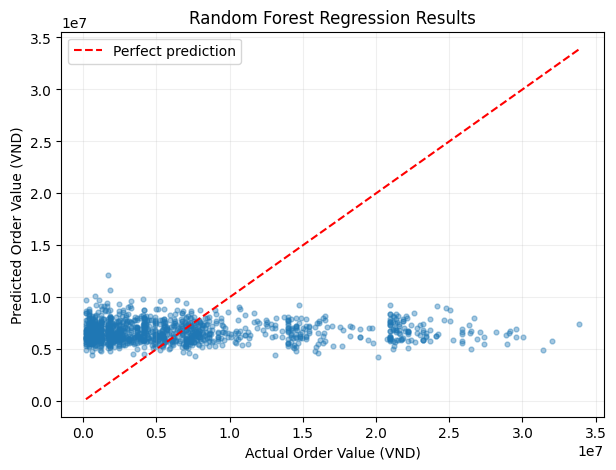

In [12]:

import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))
plt.scatter(
    y_test, y_pred,
    alpha=0.4, s=12
)

minimum = min(y_test.min(), y_pred.min())
maximum = max(y_test.max(), y_pred.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    "r--",
    label="Perfect prediction"
)

plt.xlabel("Actual Order Value (VND)")
plt.ylabel("Predicted Order Value (VND)")
plt.title("Random Forest Regression Results")
plt.legend()
plt.grid(alpha=0.2)
plt.show()


In [13]:

import joblib
from google.colab import files

joblib.dump(
    model_reg,
    "regression_model.joblib"
)

files.download("regression_model.joblib")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [14]:

print("===== DỮ LIỆU KHÁCH HÀNG =====")
print(customers.columns.tolist())

display(customers.head())

print("\n===== DỮ LIỆU ĐƠN HÀNG =====")
print(orders.columns.tolist())

display(orders.head(3))


===== DỮ LIỆU KHÁCH HÀNG =====
['customer_id', 'name', 'email', 'phone', 'address']


,customer_id,name,email,phone,address
0,1,Nguyễn Thị Hoa,user1@example.net,940272212,"{'street': 'Số 15 Lê Văn Sỹ', 'ward': 'Phường ..."
1,2,Nguyễn Mai Lê,NaN,943569728,"{'street': 'Số 39 Lê Văn Sỹ', 'ward': 'Phường ..."
2,3,Phạm Văn Nam,user3@example.net,971278402,"{'street': 'Số 95 Lê Văn Sỹ', 'ward': 'Phường ..."
3,4,Nguyễn Quang Bùi,user4@example.net,962696905,"{'street': 'Số 53 Lê Văn Sỹ', 'ward': 'Phường ..."
4,5,Hải Thị Hoa,user5@example.net,927003456,"{'street': 'Số 98 Lê Văn Sỹ', 'ward': 'Phường ..."



===== DỮ LIỆU ĐƠN HÀNG =====
['order_id', 'customer_id', 'order_date', 'status', 'shipping_address', 'total_amount', 'items']


,order_id,customer_id,order_date,status,shipping_address,total_amount,items
0,1,365,2026-01-13 03:08:00,Completed,"456 Lê Duẩn, Quận Thanh Khê, Đà Nẵng",3370000.0,"[{'product_id': '66e3c0012222222222222203', 'p..."
1,2,254,2026-07-04 14:05:00,Completed,Chưa cập nhật,8590000.0,"[{'product_id': '66e3c0012222222222222204', 'p..."
2,3,708,2026-07-31 17:56:00,Completed,"81 Khóm 13 Bà Triệu, Phường 5, Quận 5, Đà Nẵng",7970000.0,"[{'product_id': '66e3c0012222222222222204', 'p..."


Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


In [15]:

import ast
import pandas as pd

print("===== MẪU ITEMS =====")
print(orders["items"].iloc[0])

print("\n===== THÔNG TIN KHÁCH HÀNG =====")
print(customers.head(3).to_string(index=False))

print("\n===== THỐNG KÊ ĐƠN HÀNG =====")
print(orders["total_amount"].describe())

# Thử chuyển items từ chuỗi thành danh sách
sample = orders["items"].iloc[0]

if isinstance(sample, str):
    try:
        sample = ast.literal_eval(sample)
    except (ValueError, SyntaxError):
        print("Chưa đọc được cấu trúc items")

print("\n===== ITEMS SAU KHI XỬ LÝ =====")
print(sample)


===== MẪU ITEMS =====
[{'product_id': '66e3c0012222222222222203', 'product_name': 'Giày Sneaker Thể Thao Êm Chân', 'quantity': 2, 'price': 620000}, {'product_id': '66e3c0012222222222222202', 'product_name': 'Bàn Phím Cơ Keychron K2', 'quantity': 1, 'price': 1850000}, {'product_id': '66e3c0012222222222222209', 'product_name': 'Kem Chống Nắng Dưỡng Ẩm', 'quantity': 1, 'price': 280000}]

===== THÔNG TIN KHÁCH HÀNG =====
 customer_id           name             email     phone                                                                                      address
           1 Nguyễn Thị Hoa user1@example.net 940272212        {'street': 'Số 15 Lê Văn Sỹ', 'ward': 'Phường 8', 'district': 'Quận 6', 'city': None}
           2  Nguyễn Mai Lê               NaN 943569728 {'street': 'Số 39 Lê Văn Sỹ', 'ward': 'Phường 5', 'district': 'Quận 9', 'city': 'Hải Phòng'}
           3   Phạm Văn Nam user3@example.net 971278402       {'street': 'Số 95 Lê Văn Sỹ', 'ward': 'Phường 2', 'district': 'Quận 12

In [16]:
[
    {
        "product_id": "...",
        "product_name": "Giày Sneaker Thể Thao Êm Chân",
        "quantity": 2,
        "price": 620000
    },
    {
        "product_id": "...",
        "product_name": "Bàn Phím Cơ Keychron K2",
        "quantity": 1,
        "price": 1850000
    }
]

[{'product_id': '...',
  'product_name': 'Giày Sneaker Thể Thao Êm Chân',
  'quantity': 2,
  'price': 620000},
 {'product_id': '...',
  'product_name': 'Bàn Phím Cơ Keychron K2',
  'quantity': 1,
  'price': 1850000}]

In [17]:

import ast
import pandas as pd
import numpy as np

data_v2 = orders.copy()

def parse_items(value):
    if isinstance(value, list):
        return value
    if isinstance(value, str):
        try:
            result = ast.literal_eval(value)
            return result if isinstance(result, list) else []
        except (ValueError, SyntaxError):
            return []
    return []

data_v2["parsed_items"] = data_v2["items"].apply(
    parse_items
)

def extract_features(items):
    valid = [
        item for item in items
        if isinstance(item, dict)
    ]

    quantities = [
        float(item.get("quantity", 0))
        for item in valid
    ]

    prices = [
        float(item.get("price", 0))
        for item in valid
    ]

    return pd.Series({
        "item_count": sum(quantities),
        "unique_products": len(valid),
        "avg_item_price": np.mean(prices) if prices else 0,
        "max_item_price": max(prices) if prices else 0
    })

item_features = data_v2["parsed_items"].apply(
    extract_features
)

data_v2 = pd.concat(
    [data_v2, item_features], axis=1
)

display(data_v2[[
    "total_amount",
    "item_count",
    "unique_products",
    "avg_item_price",
    "max_item_price"
]].head())


,total_amount,item_count,unique_products,avg_item_price,max_item_price
0,3370000.0,4.0,3.0,9.166667e+05,1850000.0
1,8590000.0,5.0,2.0,1.535000e+06,2450000.0
2,7970000.0,4.0,2.0,1.535000e+06,2450000.0
3,560000.0,2.0,1.0,2.800000e+05,280000.0
4,3090000.0,3.0,2.0,1.235000e+06,1850000.0


In [18]:

data_v2["calculated_total"] = data_v2[
    "parsed_items"
].apply(
    lambda items: sum(
        float(i.get("quantity", 0)) *
        float(i.get("price", 0))
        for i in items
        if isinstance(i, dict)
    )
)

difference = (
    data_v2["total_amount"] -
    data_v2["calculated_total"]
).abs()

print("Số đơn có tổng tiền trùng khớp:",
      (difference < 1).sum())

print("Tổng số đơn:", len(data_v2))

print("Tỷ lệ trùng khớp:",
      round((difference < 1).mean() * 100, 2), "%")

print("Sai lệch lớn nhất:", difference.max())


Số đơn có tổng tiền trùng khớp: 5834
Tổng số đơn: 5945
Tỷ lệ trùng khớp: 98.13 %
Sai lệch lớn nhất: 20950000.0


In [19]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

features_v2 = [
    "item_count",
    "unique_products",
    "avg_item_price",
    "max_item_price"
]

X_v2 = data_v2[features_v2]
y_v2 = data_v2["total_amount"]

X_train_v2, X_test_v2, y_train_v2, y_test_v2 = (
    train_test_split(
        X_v2, y_v2,
        test_size=0.2,
        random_state=42
    )
)

model_v2 = RandomForestRegressor(
    n_estimators=200,
    max_depth=12,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

model_v2.fit(X_train_v2, y_train_v2)

pred_v2 = model_v2.predict(X_test_v2)

print("===== RANDOM FOREST V2 =====")
print("MAE:", round(
    mean_absolute_error(y_test_v2, pred_v2)
))
print("RMSE:", round(
    np.sqrt(mean_squared_error(y_test_v2, pred_v2))
))
print("R2:", round(
    r2_score(y_test_v2, pred_v2), 4
))


===== RANDOM FOREST V2 =====
MAE: 1071749
RMSE: 2108147
R2: 0.9031


In [20]:

difference = (
    data_v2["total_amount"] -
    data_v2["calculated_total"]
).abs()

match_rate = (difference < 1).mean() * 100

print("===== KIỂM TRA GIÁ TRỊ ĐƠN HÀNG =====")
print(f"Tỷ lệ trùng khớp: {match_rate:.2f}%")
print(f"Sai lệch trung bình: {difference.mean():,.0f} VNĐ")
print(f"Sai lệch lớn nhất: {difference.max():,.0f} VNĐ")


===== KIỂM TRA GIÁ TRỊ ĐƠN HÀNG =====
Tỷ lệ trùng khớp: 98.13%
Sai lệch trung bình: 95,255 VNĐ
Sai lệch lớn nhất: 20,950,000 VNĐ


In [21]:

# Tính sai lệch giữa tổng tiền thực tế và tổng từ items
data_v2["difference"] = (
    data_v2["total_amount"] -
    data_v2["calculated_total"]
)

# Lọc các đơn có sai lệch
error_orders = data_v2[
    data_v2["difference"].abs() >= 1
].copy()

# Sắp xếp theo độ lớn sai lệch
error_orders = error_orders.reindex(
    error_orders["difference"].abs()
    .sort_values(ascending=False).index
)

print("Số đơn hàng sai lệch:", len(error_orders))

display(error_orders[[
    "order_id",
    "total_amount",
    "calculated_total",
    "difference"
]].head(10))


Số đơn hàng sai lệch: 111


,order_id,total_amount,calculated_total,difference
3708,3747,4170000.0,25120000.0,-20950000.0
1758,1771,4170000.0,24520000.0,-20350000.0
3245,3279,4170000.0,22670000.0,-18500000.0
5393,5444,4170000.0,22490000.0,-18320000.0
2383,2405,4170000.0,21590000.0,-17420000.0
1353,1363,4170000.0,21250000.0,-17080000.0
4750,4795,4170000.0,20970000.0,-16800000.0
451,454,4170000.0,19070000.0,-14900000.0
1102,1109,4170000.0,18250000.0,-14080000.0
2361,2383,4170000.0,16020000.0,-11850000.0


In [22]:

# Kiểm tra các đơn sai lệch có cùng giá trị 4.170.000 không

median_value = data_v2["total_amount"].median()

print("Median:", median_value)

print("Tổng số đơn sai lệch:", len(error_orders))

print("\nCác giá trị total_amount xuất hiện nhiều nhất")
print(
    error_orders["total_amount"]
    .value_counts()
    .head(10)
)

print("\nSố đơn sai lệch có total_amount bằng median:")
print(
    (error_orders["total_amount"] == median_value).sum()
)


Median: 4170000.0
Tổng số đơn sai lệch: 111

Các giá trị total_amount xuất hiện nhiều nhất
total_amount
4170000.0    111
Name: count, dtype: int64

Số đơn sai lệch có total_amount bằng median:
111


In [23]:

# Tạo dữ liệu riêng cho TV4, không sửa file TV2
reg_data = data_v2.copy()

# Chỉ giữ các đơn có tổng tiền khớp với items
reg_data = reg_data[
    (reg_data["total_amount"] -
     reg_data["calculated_total"]).abs() < 1
].copy()

print("Số đơn ban đầu:", len(data_v2))
print("Số đơn dùng huấn luyện:", len(reg_data))
print("Số đơn tạm loại:", len(data_v2) - len(reg_data))


Số đơn ban đầu: 5945
Số đơn dùng huấn luyện: 5834
Số đơn tạm loại: 111


In [24]:

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

features_v3 = [
    "item_count",
    "unique_products",
    "avg_item_price",
    "max_item_price"
]

X = reg_data[features_v3]
y = reg_data["total_amount"]

X_train_v3, X_test_v3, y_train_v3, y_test_v3 = (
    train_test_split(
        X, y,
        test_size=0.2,
        random_state=42
    )
)

model_v3 = RandomForestRegressor(
    n_estimators=200,
    max_depth=12,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

model_v3.fit(X_train_v3, y_train_v3)

pred_v3 = model_v3.predict(X_test_v3)

print("===== RANDOM FOREST V3 =====")
print("MAE:", round(
    mean_absolute_error(y_test_v3, pred_v3)
))
print("RMSE:", round(
    np.sqrt(mean_squared_error(y_test_v3, pred_v3))
))
print("R2:", round(
    r2_score(y_test_v3, pred_v3), 4
))


===== RANDOM FOREST V3 =====
MAE: 962306
RMSE: 1956974
R2: 0.9222


In [25]:

import pandas as pd

# Dùng dữ liệu đầy đủ, không loại 111 đơn
# vì chúng chưa chắc sai về trạng thái
cls_data = data_v2.copy()

# Chỉ giữ các đơn có trạng thái cuối cùng
cls_data = cls_data[
    cls_data["status"].isin([
        "Completed", "Cancelled"
    ])
].copy()

# Tạo biến mục tiêu
cls_data["is_cancelled"] = (
    cls_data["status"] == "Cancelled"
).astype(int)

features_cls = [
    "item_count",
    "unique_products",
    "avg_item_price",
    "max_item_price"
]

X_cls = cls_data[features_cls]
y_cls = cls_data["is_cancelled"]

print("Số đơn:", len(cls_data))
print("Số đơn hoàn thành:",
      (y_cls == 0).sum())
print("Số đơn hủy:",
      (y_cls == 1).sum())

display(X_cls.head())


Số đơn: 3989
Số đơn hoàn thành: 2993
Số đơn hủy: 996


,item_count,unique_products,avg_item_price,max_item_price
0,4.0,3.0,9.166667e+05,1850000.0
1,5.0,2.0,1.535000e+06,2450000.0
2,4.0,2.0,1.535000e+06,2450000.0
5,3.0,1.0,1.900000e+05,190000.0
7,1.0,1.0,2.800000e+05,280000.0


In [28]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

model_cls = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

model_cls.fit(X_train_cls, y_train_cls)

pred_cls = model_cls.predict(X_test_cls)

print("===== RANDOM FOREST CLASSIFICATION =====")

print("Accuracy:", round(
    accuracy_score(y_test_cls, pred_cls), 4
))
print("Precision:", round(
    precision_score(y_test_cls, pred_cls, zero_division=0), 4
))
print("Recall:", round(
    recall_score(y_test_cls, pred_cls, zero_division=0), 4
))
print("F1:", round(
    f1_score(y_test_cls, pred_cls, zero_division=0), 4
))

print("\nBÁO CÁO CHI TIẾT:")
print(classification_report(
    y_test_cls, pred_cls, zero_division=0
))


===== RANDOM FOREST CLASSIFICATION =====
Accuracy: 0.5639
Precision: 0.2508
Recall: 0.3769
F1: 0.3012

BÁO CÁO CHI TIẾT:
              precision    recall  f1-score   support

           0       0.75      0.63      0.68       599
           1       0.25      0.38      0.30       199

    accuracy                           0.56       798
   macro avg       0.50      0.50      0.49       798
weighted avg       0.63      0.56      0.59       798



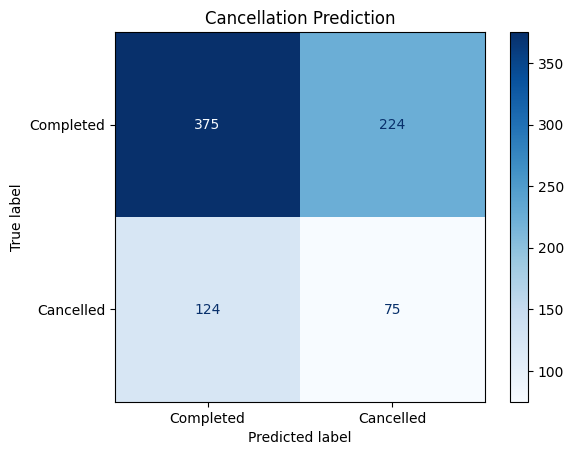

In [29]:

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test_cls,
    pred_cls,
    display_labels=["Completed", "Cancelled"],
    cmap="Blues"
)

plt.title("Cancellation Prediction")
plt.show()


,Feature,Importance
2,avg_item_price,0.494869
0,item_count,0.356684
3,max_item_price,0.091570
1,unique_products,0.056877


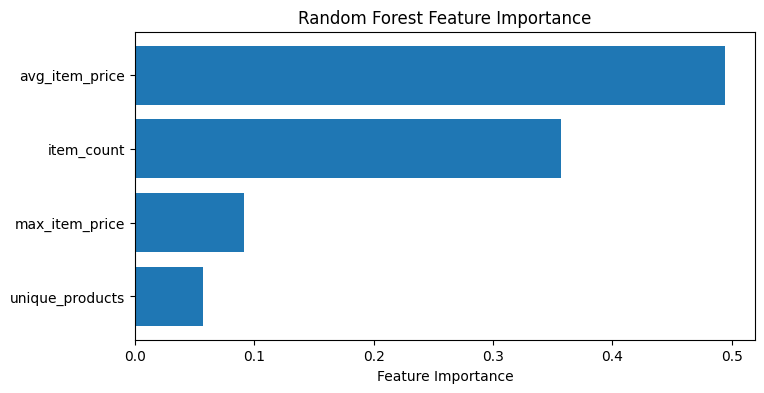

In [30]:

import pandas as pd
import matplotlib.pyplot as plt

importance = pd.DataFrame({
    "Feature": features_cls,
    "Importance": model_cls.feature_importances_
}).sort_values(
    "Importance", ascending=False
)

display(importance)

plt.figure(figsize=(8, 4))
plt.barh(
    importance["Feature"],
    importance["Importance"]
)
plt.gca().invert_yaxis()
plt.xlabel("Feature Importance")
plt.title("Random Forest Feature Importance")
plt.show()


In [31]:

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from sklearn.metrics import accuracy_score

model_logistic = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

model_logistic.fit(
    X_train_cls, y_train_cls
)

pred_logistic = model_logistic.predict(X_test_cls)

print("===== LOGISTIC REGRESSION =====")
print("Accuracy:", round(
    accuracy_score(y_test_cls, pred_logistic), 4
))

print(classification_report(
    y_test_cls,
    pred_logistic,
    zero_division=0
))


===== LOGISTIC REGRESSION =====
Accuracy: 0.7506
              precision    recall  f1-score   support

           0       0.75      1.00      0.86       599
           1       0.00      0.00      0.00       199

    accuracy                           0.75       798
   macro avg       0.38      0.50      0.43       798
weighted avg       0.56      0.75      0.64       798



In [32]:

from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score
)
import numpy as np
import pandas as pd

baseline_pred = np.zeros(len(y_test_cls), dtype=int)

models_result = pd.DataFrame([
    {
        "Model": name,
        "Accuracy": accuracy_score(y_test_cls, pred),
        "Precision": precision_score(
            y_test_cls, pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test_cls, pred, zero_division=0
        ),
        "F1": f1_score(
            y_test_cls, pred, zero_division=0
        )
    }
    for name, pred in [
        ("Baseline", baseline_pred),
        ("Random Forest", pred_cls),
        ("Logistic Regression", pred_logistic)
    ]
])

display(models_result.round(4))


,Model,Accuracy,Precision,Recall,F1
0,Baseline,0.7506,0.0000,0.0000,0.0000
1,Random Forest,0.5639,0.2508,0.3769,0.3012
2,Logistic Regression,0.7506,0.0000,0.0000,0.0000


In [33]:

import pandas as pd
import numpy as np

cls_v2 = data_v2.copy()

cls_v2["order_date"] = pd.to_datetime(
    cls_v2["order_date"], errors="coerce"
)

cls_v2 = cls_v2.dropna(
    subset=["order_date", "customer_id"]
).copy()

cls_v2 = cls_v2.sort_values(
    ["order_date", "order_id"]
).reset_index(drop=True)

# Thông tin có sẵn khi đặt hàng
cls_v2["month"] = cls_v2["order_date"].dt.month
cls_v2["day_of_week"] = cls_v2["order_date"].dt.dayofweek
cls_v2["hour"] = cls_v2["order_date"].dt.hour

# Số đơn trước đó của khách hàng
cls_v2["previous_orders"] = (
    cls_v2.groupby("customer_id").cumcount()
)

# Chỉ lấy đơn đã có kết quả cuối cùng
cls_v2 = cls_v2[
    cls_v2["status"].isin(["Completed", "Cancelled"])
].copy()

cls_v2["is_cancelled"] = (
    cls_v2["status"] == "Cancelled"
).astype(int)

features_cls_v2 = [
    "item_count",
    "unique_products",
    "avg_item_price",
    "max_item_price",
    "month",
    "day_of_week",
    "hour",
    "previous_orders"
]

display(cls_v2[features_cls_v2].head())


,item_count,unique_products,avg_item_price,max_item_price,month,day_of_week,hour,previous_orders
0,4.0,2.0,1.065000e+06,1850000.0,1,3,0,0
1,1.0,1.0,8.500000e+05,850000.0,1,3,1,0
2,6.0,3.0,2.486667e+06,6990000.0,1,3,3,0
3,3.0,3.0,4.400000e+05,850000.0,1,3,3,0
4,2.0,1.0,1.900000e+05,190000.0,1,3,4,0


In [34]:

split_idx = int(len(cls_v2) * 0.8)

X_train_new = cls_v2[features_cls_v2].iloc[:split_idx]
X_test_new = cls_v2[features_cls_v2].iloc[split_idx:]

y_train_new = cls_v2["is_cancelled"].iloc[:split_idx]
y_test_new = cls_v2["is_cancelled"].iloc[split_idx:]

print("Train:", X_train_new.shape)
print("Test:", X_test_new.shape)
print("Tỷ lệ hủy trong test:", y_test_new.mean())


Train: (3191, 8)
Test: (798, 8)
Tỷ lệ hủy trong test: 0.24060150375939848


In [35]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

model_cls_v2 = RandomForestClassifier(
    n_estimators=200,
    max_depth=8,
    min_samples_leaf=10,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

model_cls_v2.fit(X_train_new, y_train_new)

pred_new = model_cls_v2.predict(X_test_new)

baseline_new = np.zeros(len(y_test_new), dtype=int)

for name, pred in [
    ("Baseline", baseline_new),
    ("Random Forest V2", pred_new)
]:
    print("\n", name)
    print("Accuracy:", round(
        accuracy_score(y_test_new, pred), 4
    ))
    print("Precision:", round(
        precision_score(y_test_new, pred, zero_division=0), 4
    ))
    print("Recall:", round(
        recall_score(y_test_new, pred, zero_division=0), 4
    ))
    print("F1:", round(
        f1_score(y_test_new, pred, zero_division=0), 4
    ))

print("\nClassification Report:")
print(classification_report(
    y_test_new, pred_new, zero_division=0
))



 Baseline
Accuracy: 0.7594
Precision: 0.0
Recall: 0.0
F1: 0.0

 Random Forest V2
Accuracy: 0.6892
Precision: 0.3133
Recall: 0.2448
F1: 0.2749

Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.83      0.80       606
           1       0.31      0.24      0.27       192

    accuracy                           0.69       798
   macro avg       0.54      0.54      0.54       798
weighted avg       0.66      0.69      0.68       798



In [37]:

import joblib
import os

# Tạo thư mục lưu mô hình
os.makedirs("models", exist_ok=True)

# Lưu mô hình hồi quy
joblib.dump(
    model_v3,
    "models/regression_model.joblib"
)

# Lưu mô hình phân loại
joblib.dump(
    model_cls_v2,
    "models/classification_model.joblib"
)

# Lưu danh sách đặc trưng tương ứng
joblib.dump(
    features_v3,
    "models/regression_features.joblib"
)

joblib.dump(
    features_cls_v2,
    "models/classification_features.joblib"
)

print("Đã lưu các file:")
print(os.listdir("models"))


Đã lưu các file:
['regression_features.joblib', 'classification_model.joblib', 'regression_model.joblib', 'classification_features.joblib']


In [38]:

import joblib

reg_model = joblib.load(
    "models/regression_model.joblib"
)

cls_model = joblib.load(
    "models/classification_model.joblib"
)

reg_features = joblib.load(
    "models/regression_features.joblib"
)

cls_features = joblib.load(
    "models/classification_features.joblib"
)

# Kiểm tra trên dữ liệu đã chuẩn bị
reg_prediction = reg_model.predict(
    X_test_v3[reg_features].head(1)
)

cls_prediction = cls_model.predict(
    X_test_new[cls_features].head(1)
)

cls_probability = cls_model.predict_proba(
    X_test_new[cls_features].head(1)
)

print("Giá trị đơn hàng dự đoán:",
      round(reg_prediction[0]), "VNĐ")

print("Dự đoán trạng thái:",
      "Cancelled" if cls_prediction[0] == 1
      else "Completed")

print("Xác suất hủy do mô hình ước tính:",
      round(cls_probability[0][1] * 100, 2), "%")


Giá trị đơn hàng dự đoán: 5269594 VNĐ
Dự đoán trạng thái: Completed
Xác suất hủy do mô hình ước tính: 35.63 %


In [39]:

from google.colab import files
import shutil

# Nén toàn bộ thư mục models
shutil.make_archive(
    "TV4_Models",
    "zip",
    "models"
)

# Tải về máy tính
files.download("TV4_Models.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [40]:

import joblib

model = joblib.load("models/regression_model.joblib")

print("Đã tải mô hình thành công!")
print("Loại mô hình:", type(model).__name__)

features = joblib.load(
    "models/regression_features.joblib"
)

print("Các biến đầu vào:", features)


Đã tải mô hình thành công!
Loại mô hình: RandomForestRegressor
Các biến đầu vào: ['item_count', 'unique_products', 'avg_item_price', 'max_item_price']


In [41]:

%%writefile supervised_model.py
from pathlib import Path
import ast
import joblib
import pandas as pd

# Đường dẫn tới thư mục mô hình
BASE_DIR = Path(__file__).resolve().parent
MODEL_DIR = BASE_DIR / "models"


def load_models():
    """Tải mô hình và danh sách biến đầu vào."""
    reg_model = joblib.load(
        MODEL_DIR / "regression_model.joblib"
    )
    cls_model = joblib.load(
        MODEL_DIR / "classification_model.joblib"
    )
    reg_features = joblib.load(
        MODEL_DIR / "regression_features.joblib"
    )
    cls_features = joblib.load(
        MODEL_DIR / "classification_features.joblib"
    )

    return reg_model, cls_model, reg_features, cls_features


def extract_item_features(items):
    """Chuyển danh sách sản phẩm thành đặc trưng ML."""
    if isinstance(items, str):
        items = ast.literal_eval(items)

    if not isinstance(items, list) or not items:
        raise ValueError("Giỏ hàng phải có ít nhất một sản phẩm")

    quantities = []
    prices = []

    for item in items:
        if not isinstance(item, dict):
            raise ValueError("Mỗi sản phẩm phải là dictionary")

        quantity = float(item["quantity"])
        price = float(item["price"])

        if quantity <= 0 or price < 0:
            raise ValueError("Số lượng và giá không hợp lệ")

        quantities.append(quantity)
        prices.append(price)

    return {
        "item_count": sum(quantities),
        "unique_products": len(items),
        "avg_item_price": sum(prices) / len(prices),
        "max_item_price": max(prices)
    }


def predict_order_value(items):
    """Ước tính giá trị giỏ hàng bằng Random Forest."""
    reg_model, _, reg_features, _ = load_models()

    features = extract_item_features(items)
    X = pd.DataFrame([features])[reg_features]

    prediction = reg_model.predict(X)[0]

    return round(float(prediction), 2)


def predict_cancellation(items, order_date, previous_orders):
    """Thử nghiệm dự đoán khả năng hủy đơn."""
    _, cls_model, _, cls_features = load_models()

    features = extract_item_features(items)

    date = pd.to_datetime(order_date)

    features.update({
        "month": date.month,
        "day_of_week": date.dayofweek,
        "hour": date.hour,
        "previous_orders": int(previous_orders)
    })

    X = pd.DataFrame([features])[cls_features]

    prediction = int(cls_model.predict(X)[0])
    probability = float(
        cls_model.predict_proba(X)[0][1]
    )

    return {
        "prediction": prediction,
        "status": "Cancelled" if prediction == 1
                  else "Completed",
        "cancel_probability": round(probability, 4)
    }


Writing supervised_model.py


In [42]:

from supervised_model import (
    predict_order_value,
    predict_cancellation
)

# Giỏ hàng ví dụ
sample_items = [
    {
        "product_id": "P001",
        "product_name": "Giày Sneaker",
        "quantity": 2,
        "price": 620000
    },
    {
        "product_id": "P002",
        "product_name": "Bàn phím cơ",
        "quantity": 1,
        "price": 1850000
    }
]

# 1. Ước tính giá trị giỏ hàng
value = predict_order_value(sample_items)

print("===== REGRESSION =====")
print(f"Giá trị dự đoán: {value:,.0f} VNĐ")

# 2. Dự đoán khả năng hủy đơn
result = predict_cancellation(
    items=sample_items,
    order_date="2026-10-24 14:30:00",
    previous_orders=3
)

print("\n===== CLASSIFICATION =====")
print("Trạng thái dự đoán:", result["status"])
print(
    "Điểm xác suất hủy:",
    f'{result["cancel_probability"] * 100:.2f}%'
)


===== REGRESSION =====
Giá trị dự đoán: 3,838,427 VNĐ

===== CLASSIFICATION =====
Trạng thái dự đoán: Completed
Điểm xác suất hủy: 46.83%


In [43]:

from google.colab import files

files.download("supervised_model.py")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [44]:

!pip install reportlab openpyxl


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 18.8 MB/s eta 0:00:00


In [45]:

%%writefile export_report.py
import io
import pandas as pd
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph,
    Spacer, Table, TableStyle
)
from reportlab.lib import colors
from reportlab.lib.styles import getSampleStyleSheet
from reportlab.lib.pagesizes import A4
from reportlab.pdfbase import pdfmetrics
from reportlab.pdfbase.ttfonts import TTFont


def prepare_report(orders):
    df = orders.copy()

    df["total_amount"] = pd.to_numeric(
        df["total_amount"], errors="coerce"
    )
    df["order_date"] = pd.to_datetime(
        df["order_date"], errors="coerce"
    )

    df = df.dropna(subset=["order_date"])

    # Doanh thu chỉ tính đơn hoàn thành
    completed = df[df["status"] == "Completed"]

    summary = pd.DataFrame([{
        "Total Orders": len(df),
        "Completed Orders": len(completed),
        "Cancelled Orders": (
            df["status"] == "Cancelled"
        ).sum(),
        "Revenue (VND)": completed["total_amount"].sum(),
        "AOV (VND)": completed["total_amount"].mean()
    }]).fillna(0)

    monthly = completed.copy()
    monthly["month"] = (
        monthly["order_date"].dt.strftime("%Y-%m")
    )

    monthly = monthly.groupby(
        "month", as_index=False
    ).agg(
        orders=("order_id", "count"),
        revenue=("total_amount", "sum")
    )

    return summary, monthly


def export_excel(orders, output_path="business_report.xlsx"):
    summary, monthly = prepare_report(orders)

    with pd.ExcelWriter(
        output_path, engine="openpyxl"
    ) as writer:
        summary.to_excel(
            writer, sheet_name="KPI Summary",
            index=False
        )
        monthly.to_excel(
            writer, sheet_name="Monthly Revenue",
            index=False
        )

    return output_path


def export_pdf(orders, output_path="business_report.pdf"):
    summary, monthly = prepare_report(orders)

    doc = SimpleDocTemplate(
        output_path, pagesize=A4
    )
    styles = getSampleStyleSheet()
    story = []

    # Nội dung PDF dùng tiếng Anh để tránh lỗi font
    story.append(Paragraph(
        "E-COMMERCE BUSINESS REPORT",
        styles["Title"]
    ))
    story.append(Spacer(1, 16))

    story.append(Paragraph(
        "Business KPI Summary",
        styles["Heading2"]
    ))

    kpi_data = [["Metric", "Value"]]

    for col in summary.columns:
        value = summary.iloc[0][col]
        if isinstance(value, (int, float)):
            value = f"{value:,.0f}"
        kpi_data.append([col, str(value)])

    kpi_table = Table(kpi_data, colWidths=[260, 190])
    kpi_table.setStyle(TableStyle([
        ("BACKGROUND", (0, 0), (-1, 0), colors.lightblue),
        ("GRID", (0, 0), (-1, -1), 0.5, colors.grey),
        ("BOTTOMPADDING", (0, 0), (-1, -1), 8),
        ("TOPPADDING", (0, 0), (-1, -1), 8),
    ]))

    story.append(kpi_table)
    story.append(Spacer(1, 20))

    story.append(Paragraph(
        "Monthly Revenue",
        styles["Heading2"]
    ))

    month_data = [["Month", "Orders", "Revenue (VND)"]]

    for _, row in monthly.iterrows():
        month_data.append([
            str(row["month"]),
            str(int(row["orders"])),
            f'{row["revenue"]:,.0f}'
        ])

    month_table = Table(
        month_data, colWidths=[100, 100, 250],
        repeatRows=1
    )
    month_table.setStyle(TableStyle([
        ("BACKGROUND", (0, 0), (-1, 0), colors.lightblue),
        ("GRID", (0, 0), (-1, -1), 0.5, colors.grey),
        ("TOPPADDING", (0, 0), (-1, -1), 6),
        ("BOTTOMPADDING", (0, 0), (-1, -1), 6),
    ]))

    story.append(month_table)
    doc.build(story)

    return output_path


Writing export_report.py


In [48]:

from export_report import export_excel, export_pdf
from google.colab import files

# Dùng bảng orders đã tải từ TV2
excel_file = export_excel(orders)
pdf_file = export_pdf(orders)

print("Đã tạo:", excel_file)
print("Đã tạo:", pdf_file)

files.download(excel_file)
files.download(pdf_file)


Đã tạo: business_report.xlsx
Đã tạo: business_report.pdf


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [49]:

files.download("export_report.py")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>